# Unfallatlas 2025: Ensemble Models for Accident Severity

**Question (same as in `tiziano_baselines.ipynb`):** given that an accident with personal injury happened, how likely is it that
someone was **killed or seriously injured**? We predict a **probability between 0 and 1** by regressing on the binary
target `severe`. A regressor trained with squared error on a 0/1 target estimates exactly this probability, and its
loss is the **Brier score**.

The baselines showed that a linear model explains only a small part of the risk. Ensembles of trees can learn
interactions (motorcycle × rural road × night) that a linear model cannot. This notebook compares the three
ensemble families, all as **regressors** and with no neural networks:

| family | idea | models |
| --- | --- | --- |
| **Bagging** | many deep trees on bootstrap samples, averaged → lower variance | `BaggingRegressor`, `RandomForestRegressor`, `ExtraTreesRegressor` |
| **Boosting** | many shallow trees in sequence, each fixing the errors of the previous ones → lower bias | `AdaBoostRegressor`, `GradientBoostingRegressor`, `HistGradientBoostingRegressor` |
| **Stacking** | a meta-model learns how to combine different models | `VotingRegressor` (plain average), `StackingRegressor` |

All models are fitted on **train** (hyperparameters tuned by cross-validation or out-of-bag scores on train) and compared
on **validation**. The **test** split stays untouched. Splits come from `tiziano_splits.ipynb`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import loguniform, randint
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    AdaBoostRegressor,
    BaggingRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
MODEL_DIR = Path("models")

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
# same colours as tiziano_baselines.ipynb; one fixed colour per model in every plot
COLORS = {"Linear regression": "#2a78d6", "Random forest": "#1baf7a",
          "Hist gradient boosting": "#eb6834", "Stacking": "#6250d6"}
REFERENCE = "#8a8983"

## 1. Load the splits

Loader copied from `tiziano_splits.ipynb`. Two more stateless features are added row by row:

* `is_weekend`: Saturday or Sunday.
* `log_density`: log of inhabitants per km². Population density spans five orders of magnitude, and the log is a
  simple urban/rural indicator. Its 134 missing values (accidents in uninhabited areas) are imputed inside the pipeline.

In [2]:
TARGET = "severe"
OUTCOME_COLS = ["severity", "severe", "killed"]


def load_split(name):
    df = pd.read_csv(
        f"data/splits/{name}.csv.gz",
        dtype={"accident_id": str, "ags": str},
        parse_dates=["date"],
    )
    df["is_weekend"] = df["weekday"].isin(["Saturday", "Sunday"]).astype(int)
    df["log_density"] = np.log1p(df["population_per_km2"])
    return df


train = load_split("train")
val = load_split("val")

y_train, y_val = train[TARGET], val[TARGET]
base_rate = y_train.mean()
print(f"train: {len(train):,} rows | val: {len(val):,} rows | base rate (train): {base_rate:.2%}")

train: 191,104 rows | val: 40,951 rows | base rate (train): 15.72%


## 2. Features and preprocessing

| group | columns | encoding |
| --- | --- | --- |
| road users | `bicycle`, `car`, `pedestrian`, `motorcycle`, `truck`, `other_vehicle`, `vulnerable`, `single_type`, `vulnerable_vs_vehicle`, `n_participant_types` | 0/1 and count, passed through |
| accident | `accident_kind`, `accident_type` | one-hot |
| location | `state_name`, `longitude`, `latitude`, `log_density` | one-hot / numeric |
| location (fine) | `district` (512 districts) | **target encoding** |
| time | `hour_sin/cos`, `month_sin/cos`, `weekday`, `is_weekend` | numeric / one-hot |
| road conditions | `light`, `road_condition` | one-hot |

**Target encoding** replaces each district with its share of severe accidents in the training data, shrunk towards the
base rate for small districts. `TargetEncoder` cross-fits this on the training data (each row is encoded with a value learned
from the *other* folds), so a district's own row does not leak its outcome into its feature. Municipalities (≈ 9,000)
are too sparse and are left out.

Trees do not need scaling, so the preprocessor only encodes and imputes. Every model below is a pipeline
`preprocessor → regressor`, so all encoding is learned from the training data only.

In [3]:
CATEGORICAL = ["state_name", "accident_kind", "accident_type", "light", "road_condition", "weekday"]
BINARY = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle",
          "vulnerable", "single_type", "vulnerable_vs_vehicle", "is_weekend"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_participant_types",
           "longitude", "latitude", "log_density"]
HIGH_CARDINALITY = ["district"]
FEATURES = CATEGORICAL + BINARY + NUMERIC + HIGH_CARDINALITY

X_train, X_val = train[FEATURES], val[FEATURES]


def make_preprocessor():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("bin", "passthrough", BINARY),
        ("num", SimpleImputer(strategy="median"), NUMERIC),
        ("te", TargetEncoder(target_type="continuous",
                             cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), HIGH_CARDINALITY),
    ], verbose_feature_names_out=False)


def make_model(regressor):
    return make_pipeline(make_preprocessor(), regressor)


print(f"{len(FEATURES)} raw features → {make_preprocessor().fit(X_train, y_train).transform(X_train.head()).shape[1]} model columns")

25 raw features → 65 model columns


## 3. Evaluation

Same metrics as the baselines:

1. **Probability quality:** Brier score (= MSE on the 0/1 target, lower is better), Brier skill score
   (improvement over always predicting the base rate) and log loss.
2. **Ranking:** ROC-AUC and PR-AUC (average precision; random = base rate ≈ 0.157).
3. **Decisions:** precision, recall and F1 when flagging accidents above a threshold.

One change from the baselines: tree ensembles nearly memorise the training rows, so a threshold chosen on *training*
predictions would be far too high. Here the F1-optimal threshold is chosen on **validation**. This makes the F1 slightly
optimistic, but equally so for every model; for the final model the validation threshold is then applied unchanged to test.

Regressors can predict slightly outside [0, 1]; predictions are clipped before scoring.

In [4]:
def predict_proba(model, X):
    return np.clip(model.predict(X), 0, 1)


def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


brier_constant = brier_score_loss(y_val, np.full(len(y_val), base_rate))
pred_val, rows = {}, []


def evaluate(name, model, family):
    p = predict_proba(model, X_val)
    pred_val[name] = p
    threshold = best_f1_threshold(y_val, p)
    flags = p >= threshold
    row = pd.Series({
        "family": family,
        "Brier": brier_score_loss(y_val, p),
        "Brier skill": 1 - brier_score_loss(y_val, p) / brier_constant,
        "log loss": log_loss(y_val, np.clip(p, 1e-6, 1 - 1e-6)),
        "ROC-AUC": roc_auc_score(y_val, p),
        "PR-AUC": average_precision_score(y_val, p),
        "threshold": threshold,
        "% flagged": flags.mean() * 100,
        "precision": precision_score(y_val, flags),
        "recall": recall_score(y_val, flags),
        "F1": f1_score(y_val, flags),
    }, name=name)
    rows[:] = [r for r in rows if r.name != name] + [row]
    return row.to_frame().T


def results_table():
    return pd.DataFrame(rows).round(4)

## 4. Reference: linear regression

The linear regression from the baselines, refitted on the new features (including the district target encoding and
population density). This is the score every ensemble has to beat.

In [5]:
linreg = make_model(LinearRegression()).fit(X_train, y_train)
evaluate("Linear regression", linreg, "reference")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Linear regression,reference,0.124644,0.059031,0.407234,0.686481,0.28128,0.180665,36.663329,0.256294,0.597887,0.358788


## 5. Bagging

Bagging (**b**ootstrap **agg**regat**ing**) trains many trees on random bootstrap samples of the training rows and
averages their predictions. A single tree has high variance (small data changes give a very different tree); averaging
many decorrelated trees cancels most of that variance while keeping the low bias.

### 5.1 One tree vs. bagged trees

`min_samples_leaf=50` keeps every leaf large enough to estimate a probability (a leaf with 3 accidents can only say 0, ⅓, ⅔ or 1).

In [6]:
tree = make_model(DecisionTreeRegressor(min_samples_leaf=50, random_state=RANDOM_STATE)).fit(X_train, y_train)
bagging = make_model(BaggingRegressor(
    DecisionTreeRegressor(min_samples_leaf=50),
    n_estimators=100, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)

pd.concat([evaluate("Single tree", tree, "single tree"), evaluate("Bagging (trees)", bagging, "bagging")])

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Single tree,single tree,0.131343,0.008453,0.507154,0.646049,0.255312,0.153846,42.587483,0.221961,0.601461,0.324259
Bagging (trees),bagging,0.12318,0.070077,0.400996,0.700368,0.297085,0.182459,34.170106,0.271064,0.589341,0.371335


### 5.2 Random forest

A random forest is bagging plus **feature subsampling**: each split only looks at a random subset of columns
(`max_features`). This decorrelates the trees further, because a dominant feature such as the kind of accident cannot sit
at the top of every tree.

**Tuning with out-of-bag (OOB) scores.** Each tree never sees about a third of the training rows (those not drawn in its
bootstrap sample). Predicting each row only with the trees that did not see it gives a free validation score on train,
without cross-validation. For a regressor the OOB score is R², and on a 0/1 target R² is the Brier skill score
against the training base rate.

In [7]:
oob_rows = []
for leaf in [20, 50, 100, 200]:
    for max_features in [0.2, 0.3, 0.5]:
        rf = make_model(RandomForestRegressor(
            n_estimators=150, min_samples_leaf=leaf, max_features=max_features,
            oob_score=True, n_jobs=-1, random_state=RANDOM_STATE,
        )).fit(X_train, y_train)
        oob_rows.append({"min_samples_leaf": leaf, "max_features": max_features,
                         "OOB Brier skill": rf[-1].oob_score_})

oob = pd.DataFrame(oob_rows)
best_rf = oob.loc[oob["OOB Brier skill"].idxmax()]
print(f"best: min_samples_leaf={best_rf['min_samples_leaf']:.0f}, max_features={best_rf['max_features']}")
oob.pivot(index="min_samples_leaf", columns="max_features", values="OOB Brier skill").round(4)

best: min_samples_leaf=50, max_features=0.2


max_features,0.2,0.3,0.5
min_samples_leaf,,,
20,0.0692,0.0678,0.0661
50,0.0700,0.0699,0.0689
100,0.0686,0.0692,0.0693
200,0.0665,0.0674,0.0678


In [8]:
random_forest = make_model(RandomForestRegressor(
    n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]),
    max_features=best_rf["max_features"], n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Random forest", random_forest, "bagging")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Random forest,bagging,0.122852,0.072554,0.400035,0.703395,0.303176,0.184115,33.610901,0.272595,0.582971,0.371485


### 5.3 Extra trees

Extremely randomised trees go one step further: split thresholds are drawn at random instead of optimised. This adds
bias but removes even more variance, and each tree is cheaper to grow. They use the full training set (no bootstrap)
by default.

In [9]:
extra_trees = make_model(ExtraTreesRegressor(
    n_estimators=400, min_samples_leaf=int(best_rf["min_samples_leaf"]), max_features=0.5,
    n_jobs=-1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Extra trees", extra_trees, "bagging")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Extra trees,bagging,0.122885,0.072309,0.400096,0.702544,0.29986,0.190064,30.866157,0.280142,0.550186,0.371252


## 6. Boosting

Boosting grows **shallow trees one after another**. Each new tree focuses on what the ensemble so far gets wrong, so
boosting mainly reduces bias. The learning rate shrinks each tree's contribution; smaller rates need more trees but
generalise better.

### 6.1 AdaBoost

`AdaBoostRegressor` (AdaBoost.R2) reweights the training rows: rows with large errors get a higher weight and are
more likely to be sampled for the next tree. The final prediction is a weighted **median** of the trees, not a mean.

In [10]:
adaboost = make_model(AdaBoostRegressor(
    DecisionTreeRegressor(max_depth=3), n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("AdaBoost", adaboost, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
AdaBoost,boosting,0.130847,0.012202,0.428955,0.660436,0.263703,0.250869,28.851554,0.258146,0.473897,0.334228


AdaBoost is the weakest ensemble here, and it is not a tuning problem. On a 0/1 target almost every row has an absolute
error close to either its probability or one minus it, so AdaBoost.R2 keeps upweighting the severe accidents, which are
mostly unpredictable noise. The weighted median also produces only a few distinct values, which hurts the ranking metrics.
**Gradient boosting** fits the residuals of the squared error directly and does not have this problem.

### 6.2 Gradient boosting

`GradientBoostingRegressor` fits each new tree to the residuals (`y − current prediction`) of the squared error.
`subsample=0.5` (stochastic gradient boosting) adds a bit of bagging: every tree sees a random half of the rows.

In [11]:
gradient_boosting = make_model(GradientBoostingRegressor(
    n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.5, random_state=RANDOM_STATE,
)).fit(X_train, y_train)
evaluate("Gradient boosting", gradient_boosting, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Gradient boosting,boosting,0.123323,0.069001,0.401787,0.699577,0.294976,0.177246,35.120021,0.269017,0.60115,0.371698


### 6.3 Histogram gradient boosting (tuned)

`HistGradientBoostingRegressor` is the same algorithm, but it bins every feature into at most 255 values first.
It is an order of magnitude faster on 190k rows (similar to LightGBM), which makes cross-validated tuning affordable.
**Early stopping** on an internal 10 % slice of the training data picks the number of trees.

Hyperparameters are tuned with a randomised search, 3-fold CV on train, scored by MSE (= Brier score).

In [12]:
search = RandomizedSearchCV(
    make_model(HistGradientBoostingRegressor(max_iter=2000, early_stopping=True,
                                             n_iter_no_change=30, random_state=RANDOM_STATE)),
    param_distributions={
        "histgradientboostingregressor__learning_rate": loguniform(0.02, 0.2),
        "histgradientboostingregressor__max_leaf_nodes": randint(8, 64),
        "histgradientboostingregressor__min_samples_leaf": randint(20, 400),
        "histgradientboostingregressor__l2_regularization": loguniform(1e-3, 10),
        "histgradientboostingregressor__max_features": [0.5, 0.75, 1.0],
    },
    n_iter=20, cv=3, scoring="neg_mean_squared_error", n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_train, y_train)

hist_gb = search.best_estimator_
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print(f"best CV Brier: {-search.best_score_:.4f} | trees after early stopping: {hist_gb[-1].n_iter_}")
pd.Series({k.split("__")[1]: v for k, v in search.best_params_.items()}).to_frame("best value")

best CV Brier: 0.1230 | trees after early stopping: 184


,best value
l2_regularization,2.065143
learning_rate,0.045476
max_features,0.500000
max_leaf_nodes,48.000000
min_samples_leaf,176.000000


In [13]:
evaluate("Hist gradient boosting", hist_gb, "boosting")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Hist gradient boosting,boosting,0.122704,0.073676,0.399302,0.704357,0.303005,0.183697,32.870992,0.27576,0.576756,0.373122


**Learning curve.** The training loss keeps falling with every tree, while the held-out loss flattens; early stopping
cuts where the held-out loss stops improving.

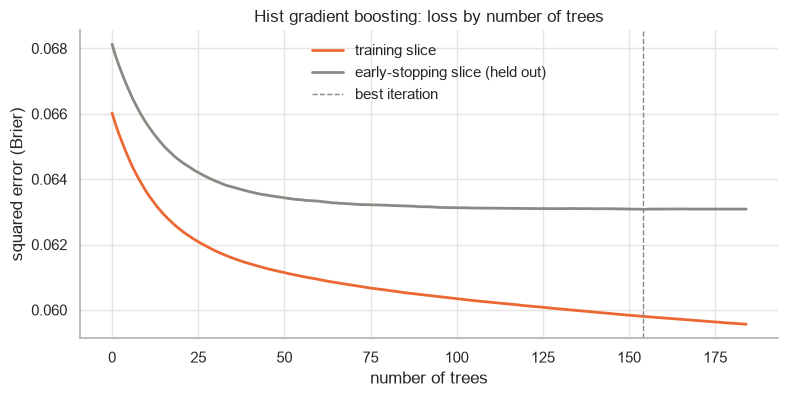

In [14]:
gb = hist_gb[-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(-gb.train_score_, lw=2, color=COLORS["Hist gradient boosting"], label="training slice")
ax.plot(-gb.validation_score_, lw=2, color=REFERENCE, label="early-stopping slice (held out)")
ax.axvline(gb.n_iter_ - gb.n_iter_no_change, color=REFERENCE, ls="--", lw=1, label="best iteration")
ax.set(xlabel="number of trees", ylabel="squared error (Brier)",
       title="Hist gradient boosting: loss by number of trees")
ax.legend(frameon=False)
plt.show()

## 7. Stacking

The models above make partly different mistakes: linear regression extrapolates smoothly, forests average local
neighbourhoods, boosting builds sharp interactions. Combining them can beat each one.

* **Voting** averages the predictions with equal weights. There is nothing to fit.
* **Stacking** trains a meta-model on the base models' **out-of-fold** predictions (5-fold CV on train), so the
  meta-model learns how far to trust each model on rows that model has not seen. The meta-model is a linear regression with
  non-negative weights: the result is an interpretable weighted average, and a model that adds nothing gets weight 0.

Base models: linear regression, random forest, extra trees and the tuned hist gradient boosting (AdaBoost and the slow
`GradientBoostingRegressor` are left out; they add nothing over hist gradient boosting).

In [15]:
base_models = [
    ("linear", linreg),
    ("random_forest", random_forest),
    ("extra_trees", extra_trees),
    ("hist_gb", hist_gb),
]

voting = VotingRegressor(base_models, n_jobs=1).fit(X_train, y_train)
evaluate("Voting (average)", voting, "stacking")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Voting (average),stacking,0.12276,0.073249,0.399415,0.704884,0.303638,0.193826,30.531611,0.282652,0.549099,0.373198


In [16]:
stacking = StackingRegressor(
    base_models,
    final_estimator=LinearRegression(positive=True),
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,  # the forests already use all cores
).fit(X_train, y_train)

meta = stacking.final_estimator_
weights = pd.Series(meta.coef_, index=[name for name, _ in base_models], name="weight")
print(f"meta-model intercept: {meta.intercept_:.4f}, sum of weights: {weights.sum():.3f}")
display(weights.round(3).to_frame())
evaluate("Stacking", stacking, "stacking")

meta-model intercept: -0.0065, sum of weights: 1.041


,weight
linear,0.020
random_forest,0.000
extra_trees,0.407
hist_gb,0.614


,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Stacking,stacking,0.122539,0.074923,0.398765,0.705748,0.304222,0.185708,32.607262,0.27814,0.577067,0.37536


## 8. Comparison on validation

In [17]:
results = results_table()
results.sort_values("Brier")

,family,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Stacking,stacking,0.1225,0.0749,0.3988,0.7057,0.3042,0.1857,32.6073,0.2781,0.5771,0.3754
Hist gradient boosting,boosting,0.1227,0.0737,0.3993,0.7044,0.3030,0.1837,32.8710,0.2758,0.5768,0.3731
Voting (average),stacking,0.1228,0.0732,0.3994,0.7049,0.3036,0.1938,30.5316,0.2827,0.5491,0.3732
Random forest,bagging,0.1229,0.0726,0.4000,0.7034,0.3032,0.1841,33.6109,0.2726,0.5830,0.3715
Extra trees,bagging,0.1229,0.0723,0.4001,0.7025,0.2999,0.1901,30.8662,0.2801,0.5502,0.3713
Bagging (trees),bagging,0.1232,0.0701,0.4010,0.7004,0.2971,0.1825,34.1701,0.2711,0.5893,0.3713
Gradient boosting,boosting,0.1233,0.0690,0.4018,0.6996,0.2950,0.1772,35.1200,0.2690,0.6011,0.3717
Linear regression,reference,0.1246,0.0590,0.4072,0.6865,0.2813,0.1807,36.6633,0.2563,0.5979,0.3588
AdaBoost,boosting,0.1308,0.0122,0.4290,0.6604,0.2637,0.2509,28.8516,0.2581,0.4739,0.3342
Single tree,single tree,0.1313,0.0085,0.5072,0.6460,0.2553,0.1538,42.5875,0.2220,0.6015,0.3243


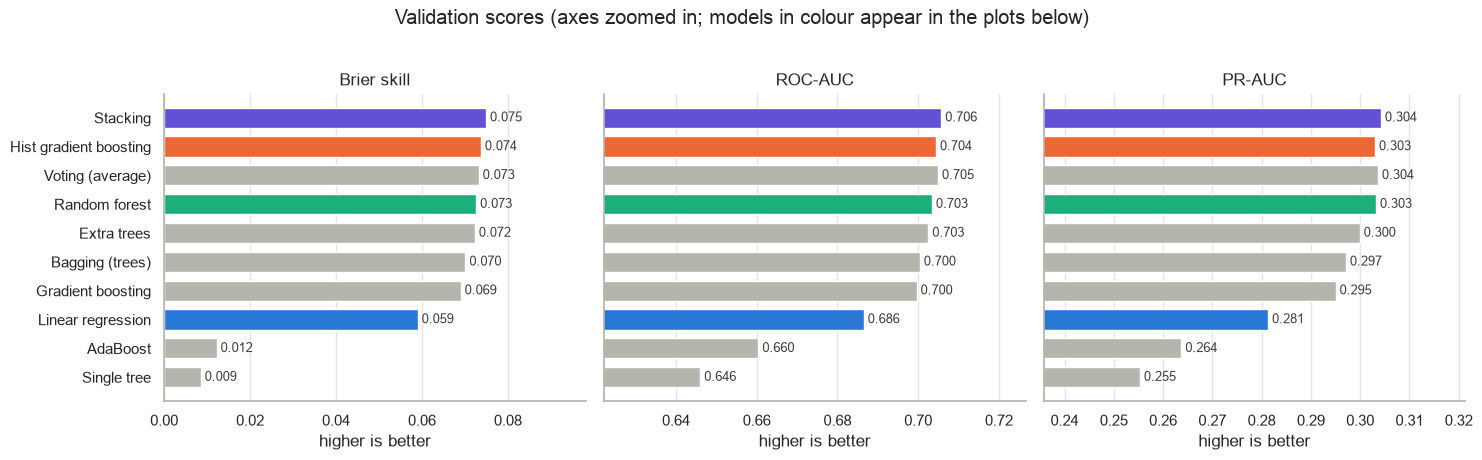

In [18]:
metrics = ["Brier skill", "ROC-AUC", "PR-AUC"]
order = results.sort_values("Brier skill").index
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, metric in zip(axes, metrics):
    values = results.loc[order, metric].astype(float)
    colors = [COLORS.get(name, "#b5b4ad") for name in order]
    ax.barh(order, values, color=colors, height=0.7)
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9, color="#3d3d3a")
    lo = values.min()
    ax.set_xlim(max(lo - (values.max() - lo) * 0.4, 0), values.max() + (values.max() - lo) * 0.35)
    ax.set(title=metric, xlabel="higher is better")
    ax.grid(axis="y", visible=False)
plt.suptitle("Validation scores (axes zoomed in; models in colour appear in the plots below)", y=1.02)
plt.tight_layout()
plt.show()

### Calibration and precision–recall

Four models in the plots: the linear reference, the best bagging model, the best boosting model and the stack.

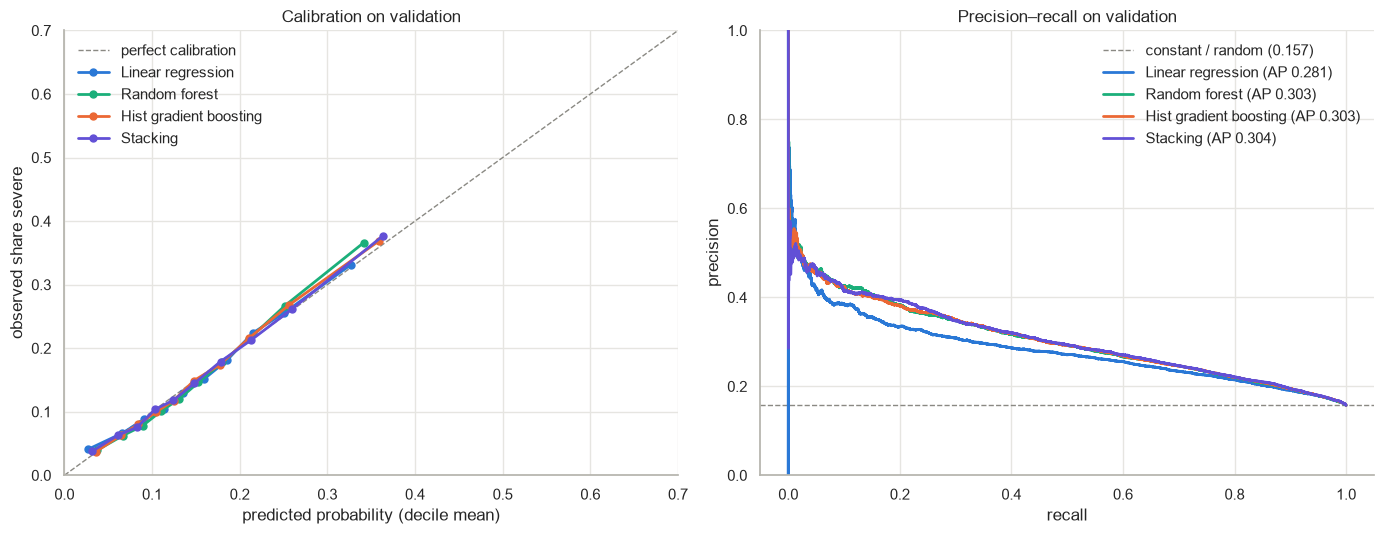

In [19]:
SHOWN = list(COLORS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.plot([0, 0.7], [0, 0.7], color=REFERENCE, ls="--", lw=1, label="perfect calibration")
for name in SHOWN:
    frac_pos, mean_pred = calibration_curve(y_val, pred_val[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=5, lw=2, color=COLORS[name], label=name)
ax.set(xlabel="predicted probability (decile mean)", ylabel="observed share severe",
       title="Calibration on validation", xlim=(0, 0.7), ylim=(0, 0.7))
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(y_val.mean(), color=REFERENCE, ls="--", lw=1, label=f"constant / random ({y_val.mean():.3f})")
for name in SHOWN:
    precision, recall, _ = precision_recall_curve(y_val, pred_val[name])
    ax.plot(recall, precision, lw=2, color=COLORS[name],
            label=f"{name} (AP {average_precision_score(y_val, pred_val[name]):.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision–recall on validation", ylim=(0, 1))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Lift by risk decile

Validation accidents sorted by predicted risk and cut into ten equal groups; bars show the observed share of severe accidents per group.

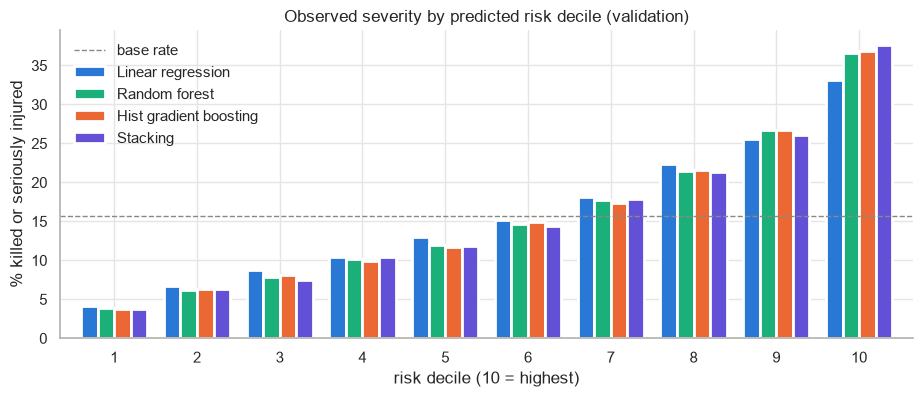

risk decile (10 = highest),1,2,3,4,5,6,7,8,9,10
Linear regression,4.1,6.6,8.8,10.4,12.9,15.2,18.1,22.4,25.5,33.1
Random forest,3.9,6.2,7.8,10.1,11.9,14.6,17.8,21.5,26.7,36.6
Hist gradient boosting,3.7,6.3,8.1,9.9,11.7,14.9,17.4,21.5,26.7,36.9
Stacking,3.8,6.3,7.5,10.4,11.8,14.5,17.9,21.3,26.1,37.6


In [20]:
lift = pd.DataFrame({
    name: pd.Series(y_val.to_numpy()).groupby(pd.qcut(pd.Series(pred_val[name]).rank(method="first"),
                                                      10, labels=range(1, 11))).mean()
    for name in SHOWN
}) * 100
lift.index.name = "risk decile (10 = highest)"

fig, ax = plt.subplots(figsize=(11, 4))
lift.plot.bar(ax=ax, color=[COLORS[c] for c in lift.columns], width=0.8, edgecolor="white", linewidth=2)
ax.axhline(y_val.mean() * 100, color=REFERENCE, ls="--", lw=1, label="base rate")
ax.set(ylabel="% killed or seriously injured", title="Observed severity by predicted risk decile (validation)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
plt.show()
lift.round(1).T

## 9. What drives the predictions

**Permutation importance** of the best single model: shuffle one raw feature on validation and measure how much
the Brier score gets worse. Unlike impurity importance it is measured on unseen data, and it is computed per raw column,
so a one-hot encoded column such as `accident_kind` counts as one feature.

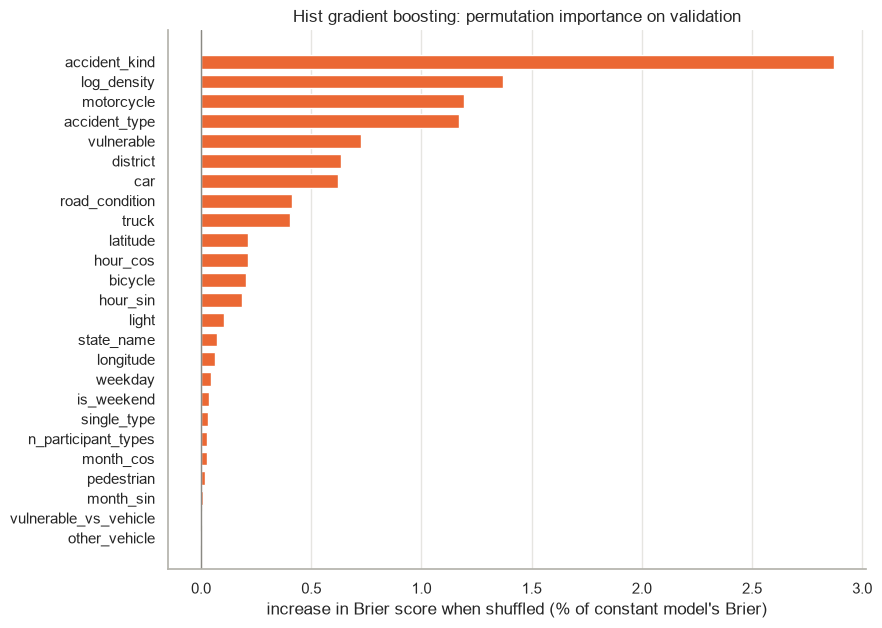

In [21]:
sample = X_val.sample(15_000, random_state=RANDOM_STATE)
importance = permutation_importance(
    hist_gb, sample, y_val.loc[sample.index], scoring="neg_mean_squared_error",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
imp = pd.Series(importance.importances_mean, index=FEATURES).sort_values()
imp = imp / brier_constant * 100  # in % of the constant model's Brier score

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp.index, imp.values, color=COLORS["Hist gradient boosting"], height=0.7)
ax.axvline(0, color=REFERENCE, lw=1)
ax.set(xlabel="increase in Brier score when shuffled (% of constant model's Brier)",
       title="Hist gradient boosting: permutation importance on validation")
ax.grid(axis="y", visible=False)
plt.show()

## 10. Save the model

Only the tuned hist gradient boosting is saved (0.5 MB), so the final notebook can score the test set without refitting.
The stack is not saved: with its 400-tree forests it is about 160 MB, which is too large for GitHub (100 MB limit), and it is only marginally better (see the summary).

In [22]:
MODEL_DIR.mkdir(exist_ok=True)
path = MODEL_DIR / "ensemble_hist_gb.joblib"
joblib.dump(hist_gb, path, compress=3)
print(f"saved {path} ({path.stat().st_size / 1e6:.1f} MB)")

saved models/ensemble_hist_gb.joblib (0.5 MB)


## 11. Summary

| | family | Brier skill | ROC-AUC | PR-AUC | F1 (val threshold) |
| --- | --- | --- | --- | --- | --- |
| Linear regression (reference) | – | 0.059 | 0.686 | 0.281 | 0.359 |
| Single tree | – | 0.008 | 0.646 | 0.255 | 0.324 |
| Bagging (trees) | bagging | 0.070 | 0.700 | 0.297 | 0.371 |
| Random forest | bagging | 0.073 | 0.703 | 0.303 | 0.371 |
| Extra trees | bagging | 0.072 | 0.703 | 0.300 | 0.371 |
| AdaBoost | boosting | 0.012 | 0.660 | 0.264 | 0.334 |
| Gradient boosting | boosting | 0.069 | 0.700 | 0.295 | 0.372 |
| **Hist gradient boosting (tuned)** | boosting | **0.074** | **0.704** | **0.303** | **0.373** |
| Voting (average) | stacking | 0.073 | 0.705 | 0.304 | 0.373 |
| **Stacking** | stacking | **0.075** | **0.706** | **0.304** | **0.375** |

* **Ensembles beat the linear reference clearly, but not dramatically.** Brier skill rises from 0.059 to 0.074 (about +25 %),
  PR-AUC from 0.281 to 0.303, and the top risk decile goes from 33 % to 37 % severe accidents (base rate 15.7 %).
  All good ensembles stay well calibrated, so their probabilities can be read at face value.
* **Bagging works because it removes variance.** A single tree is barely better than the constant model (Brier skill 0.008);
  100 bagged copies of the same tree reach 0.070. Feature subsampling (random forest) adds a little more.
* **Boosting:** the tuned hist gradient boosting is the best single model and trains in seconds. AdaBoost.R2 is a poor fit
  for a 0/1 target, because it keeps upweighting severe accidents that are mostly unpredictable.
* **Stacking gives the best scores, but only by a hair** (+0.001 Brier skill over hist gradient boosting). The meta-model puts
  0.61 on hist gradient boosting, 0.41 on extra trees and nothing on the random forest (it duplicates extra trees). The gains
  between the good ensembles are about the size of the validation noise, so the ranking among them is not reliable.
* **The models agree on what matters:** kind of accident, population density (urban vs. rural), motorcycle involved and
  accident type. `log_density` is new in this notebook and is the second most important feature, which confirms that the
  state effects in the linear baseline were largely an urban/rural proxy.

**Recommendation:** carry **hist gradient boosting** forward as the main model. It is practically as good as the stack,
0.5 MB instead of 160 MB, fast to retrain and simpler to explain. Keep the stack as a "best possible" reference.

**Next steps:** error analysis on validation (which kinds of severe accidents get low scores?); try `HistGradientBoostingRegressor`
with native categorical support instead of one-hot; an urban/rural × road-user interaction check; then score the **test set once**
with the saved model and the validation threshold (0.184).